# When Hedges Break: Stress-Testing Crypto Pairs Trading

### 1 · Data and crash periods

**Motivation.** During a crash, many of these coins fall together. A pairs trade holds the difference between two of them. That difference depends on a hedge ratio estimated from past prices, and the ratio is not one. This notebook measures the common move, the unit gap, and the fitted gap. The trading rules are in notebook 3.

| Notebook | Content |
|---|---|
| **1 · Data and crash periods** (this one) | data, crash windows, how pairs behave in crashes, GARCH-t volatility filter |
| 2 · Cointegration diagnostics | which pairs are cointegrated, how stable that is, regression direction, volatility regimes |
| 3 · Three strategies, walk-forward | static vs dynamic (OU) vs dynamic + GARCH filter; VaR/CVaR; normal vs stressed periods |
| 4 · Historical crashes | each crash, two single-coin shocks (XMR delisting 2024, ZEC surge 2025), filter timing |
| 5 · Monte Carlo stress scenarios | volatility spike, cointegration breakdown, high costs, temporary and permanent single-coin shocks |
| 6 · Robustness and conclusions | sensitivity, confidence intervals, multiple-testing check |

The two-page summary is `summary/executive_summary.pdf`. The seven slides are `slides/when_hedges_break.pdf`.

## Data

* **Universe:** eight liquid altcoins with daily history back to 2018: **BNB, LINK, LTC, TRX, BCH, XLM, XMR, ZEC**, which give **28 pairs**. The eight names are a chosen sample, not the eight most liquid altcoins. The regression direction is median reported spot volume through 31 December 2019, most liquid first: LTC, BCH, TRX, XMR, BNB, ZEC, XLM, LINK. A ranking on 2020–2026 volume would use volume from inside the backtest, so it is not used. The sample excludes:
  * BTC and ETH, which drive the common market factor and dominate the published work on crypto pairs;
  * XRP, ADA, DOGE and ETC, which are covered in Yu (2026), the dissertation whose modelling framework this project builds on;
  * EOS, whose reported volume fell to zero after its 2025 rebrand.

  This is a different cross-section from the earlier crash study, not a later period held out from that study. The universe also mixes economic groups, so we can ask whether economically linked coins pair better: payment coins (LTC, BCH, XLM), privacy coins (XMR, ZEC), smart-contract platforms (BNB, TRX) and oracle infrastructure (LINK).
* **Source:** Coin Metrics Community Data: daily USD reference rate (00:00 UTC) and reported spot volume, free and with no API key. The processed panels `data/prices.csv` and `data/volumes.csv` are committed so every notebook runs offline.
* **Period:** prices from Jul 2017 for estimation. **All trading results run 1 Jan 2020 – 23 May 2026.**

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from cryptopairs import plotting as P
from cryptopairs.project import setup, START
from cryptopairs.risk import EVENTS, event_mask, high_vol_regime, garch_t_forecasts
P.set_style()
pd.set_option("display.precision", 3, "display.width", 170)
px, vol, mkt, sig, risk_off = setup()
print(px.shape, px.index.min().date(), "->", px.index.max().date())

(3249, 8) 2017-07-01 -> 2026-05-23


In [2]:
info = pd.DataFrame({
    "first price": px.apply(lambda s: s.first_valid_index().date()),
    "price on 23 May 2026 ($)": px.iloc[-1].round(3),
    "median daily volume 2020-26 ($M)": (vol.loc[START:].median() / 1e6).round(0),
    "ann. volatility 2020-26": np.log(px).diff().loc[START:].std() * np.sqrt(365),
    "group": px.columns.map({"LTC": "payments", "BCH": "payments", "XLM": "payments", "XMR": "privacy", "ZEC": "privacy", "BNB": "platform", "TRX": "platform", "LINK": "oracle"}),
})
info

,first price,price on 23 May 2026 ($),median daily volume 2020-26 ($M),ann. volatility 2020-26,group
LTC,2017-07-01,53.440,206.0,0.873,payments
BCH,2017-08-01,355.173,131.0,0.941,payments
TRX,2018-06-25,0.362,153.0,0.802,platform
XMR,2017-07-01,386.556,56.0,0.842,privacy
BNB,2017-07-15,655.775,412.0,0.814,platform
ZEC,2017-07-01,634.279,34.0,1.121,privacy
XLM,2017-07-01,0.148,66.0,0.958,payments
LINK,2017-09-29,9.556,217.0,1.041,oracle


## Market stress periods

Five named crash windows, each running about a month from just before the trigger:

| Window | Trigger |
|---|---|
| COVID crash, 8 Mar – 7 Apr 2020 | global risk-off; the 12 Mar sell-off |
| May 2021 crash, 10 May – 9 Jun 2021 | Tesla suspends BTC payments (12 May), China crackdown on mining; 19 May crash |
| Terra/LUNA, 5 May – 4 Jun 2022 | UST loses its dollar peg (7–9 May) and LUNA collapses |
| FTX collapse, 5 Nov – 5 Dec 2022 | FTX halts withdrawals (8 Nov) and files for bankruptcy (11 Nov) |
| Oct 2025 liquidations, 6 Oct – 5 Nov 2025 | 10 Oct tariff shock and the largest liquidation event on record (about $19B of leveraged positions) |

A **reporting label** sits beside those windows. A day is in the *high-volatility regime* when the trailing 30-day realised volatility of the mean log-return factor is in the top 20% of that factor's history. Before 25 June 2018 the mean uses fewer than eight coins, because TRX has no price yet. The five windows and this label are defined with hindsight and are used only to report results. Neither one is the GARCH trading signal. That signal is a one-day-ahead forecast built from past returns, and it is described in the filter section below.

In [3]:
ev = event_mask(px.index)
hv = high_vol_regime(mkt)
rows = []
for name, (a, b) in EVENTS.items():
    idx_lvl = np.exp(mkt.loc[a:b].cumsum())
    coin_dd = (px.loc[a:b] / px.loc[a:b].cummax() - 1).min()
    rows.append({"event": name, "window": f"{a} to {b}",
                 "mean-log-factor drawdown": (idx_lvl / idx_lvl.cummax() - 1).min(),
                 "worst day (log return)": mkt.loc[a:b].min(),
                 "worst day date": mkt.loc[a:b].idxmin().date(),
                 "hardest-hit coin": f"{coin_dd.idxmin()} ({coin_dd.min():.0%})",
                 "share of days in high-vol regime": hv.loc[a:b].mean()})
events = pd.DataFrame(rows).set_index("event")
print(f"High-volatility regime: {hv.loc[START:].mean():.0%} of days since 2020")
events

High-volatility regime: 13% of days since 2020


,window,mean-log-factor drawdown,worst day (log return),worst day date,hardest-hit coin,share of days in high-vol regime
event,,,,,,
COVID crash (Mar 2020),2020-03-08 to 2020-04-07,-0.423,-0.507,2020-03-12,LINK (-57%),0.871
May 2021 crash,2021-05-10 to 2021-06-09,-0.579,-0.403,2021-05-19,BCH (-63%),1.000
Terra/LUNA (May 2022),2022-05-05 to 2022-06-04,-0.314,-0.170,2022-05-09,LINK (-43%),0.806
FTX collapse (Nov 2022),2022-11-05 to 2022-12-05,-0.266,-0.165,2022-11-09,LINK (-35%),0.258
Oct 2025 liquidations,2025-10-06 to 2025-11-05,-0.160,-0.119,2025-10-10,LINK (-37%),0.000


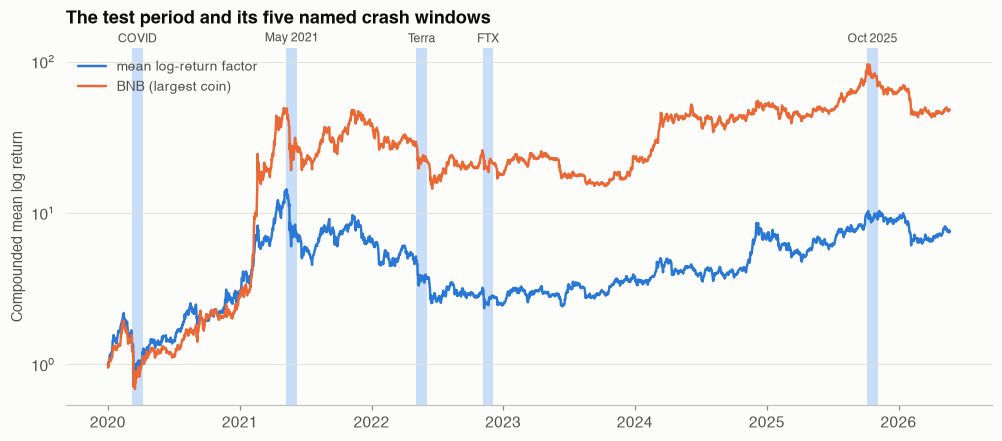

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.9))
lvl = np.exp(mkt.loc[START:].cumsum())
ax.plot(lvl.index, lvl, color=P.C[0], label="mean log-return factor")
bnb = px.BNB.loc[START:] / px.BNB.loc[START]
ax.plot(bnb.index, bnb, color=P.C[1], label="BNB (largest coin)")
short = {"COVID crash (Mar 2020)": "COVID", "May 2021 crash": "May 2021", "Terra/LUNA (May 2022)": "Terra",
         "FTX collapse (Nov 2022)": "FTX", "Oct 2025 liquidations": "Oct 2025"}
for name, (a, b) in EVENTS.items():
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=P.SEQ[1], alpha=0.55, lw=0, zorder=0)
    mid = pd.Timestamp(a) + (pd.Timestamp(b) - pd.Timestamp(a)) / 2
    ax.text(mid, 1.01, short[name], transform=ax.get_xaxis_transform(), fontsize=8, color=P.INK2,
            ha="center", va="bottom")
ax.set_yscale("log"); ax.set_ylabel("Compounded mean log return")
ax.set_title("The test period and its five named crash windows", pad=16)
ax.legend(loc="upper left")
P.save(fig, "01_crash_windows")

## What changes for a pairs trader in a crash

A pairs trade bets that the *relative* price of two coins reverts. Two things can break that bet in a crash: volatility jumps, so spreads swing further than the model expects, or one coin is hit much harder than the other.

In [5]:
r = np.log(px).diff().loc[START:]
def avg_corr(x):
    c = x.corr().to_numpy()
    return c[np.triu_indices_from(c, 1)].mean()
cols = list(px.columns)
pair_diff = pd.DataFrame({f"{cols[j]}-{cols[i]}": r[cols[j]] - r[cols[i]]
                          for i in range(len(cols)) for j in range(i + 1, len(cols))})
m = ev.reindex(r.index).fillna(False)
comp = pd.DataFrame({
    "average pairwise return correlation": [avg_corr(r[m]), avg_corr(r[~m])],
    "index daily vol (ann.)": [r[m].mean(axis=1).std() * np.sqrt(365), r[~m].mean(axis=1).std() * np.sqrt(365)],
    "median vol of pair return differences (ann.)": [pair_diff[m].std().median() * np.sqrt(365),
                                                     pair_diff[~m].std().median() * np.sqrt(365)],
}, index=["crash windows", "all other days"]).T
comp["ratio crash / other"] = comp["crash windows"] / comp["all other days"]
comp.loc["average pairwise return correlation", "ratio crash / other"] = float("nan")
comp["ratio crash / other"] = comp["ratio crash / other"].map(lambda x: "" if pd.isna(x) else round(float(x), 2))
comp

,crash windows,all other days,ratio crash / other
average pairwise return correlation,0.840,0.535,
index daily vol (ann.),1.515,0.656,2.31
median vol of pair return differences (ann.),0.882,0.826,1.07


In the pooled crash windows the coins move together: average correlation is about 0.84 against about 0.54 on the other days, and the volatility of the mean log return more than doubles. The unit gap r_i - r_j rises much less. That gap is not the traded hedge. The traded position uses a fitted ratio and is scaled to gross exposure, so it is not dollar-neutral. The five windows are not equally strong; October 2025 is much less correlated than March 2020.

The danger is the exception: one coin moving on its own news, as XMR did when Binance announced its delisting in February 2024, or ZEC during its late-2025 surge (notebook 4). That risk is pair-specific, so a filter driven by *market* volatility may not see it coming.

## Volatility model: GARCH(1,1) with Student-t innovations

Full-sample fits for each coin and for the mean log-return factor. These fits describe the sample. The trading forecast is the rolling one below. A value of α + β close to 1 means volatility shocks die out slowly; a low ν (degrees of freedom of the Student-t) means heavy tails.

In [6]:
from arch import arch_model
rows = {}
for c in list(px.columns) + ["mean log-return factor"]:
    x = 100 * (mkt if c == "mean log-return factor" else np.log(px[c]).diff()).loc["2018-07-01":].dropna()
    p = arch_model(x, mean="Constant", vol="GARCH", p=1, q=1, dist="t").fit(disp="off").params
    rows[c] = {"omega": p["omega"], "alpha": p["alpha[1]"], "beta": p["beta[1]"],
               "alpha+beta": p["alpha[1]"] + p["beta[1]"], "t d.o.f. (nu)": p["nu"]}
pd.DataFrame(rows).T

,omega,alpha,beta,alpha+beta,t d.o.f. (nu)
LTC,0.685,0.097,0.890,0.987,3.324
BCH,1.586,0.117,0.850,0.967,3.022
TRX,0.253,0.160,0.840,1.000,3.507
XMR,0.427,0.149,0.851,1.000,3.709
BNB,0.349,0.137,0.863,1.000,3.621
ZEC,0.764,0.094,0.893,0.987,3.978
XLM,1.041,0.154,0.826,0.981,3.509
LINK,0.976,0.095,0.876,0.971,5.383
mean log-return factor,0.484,0.108,0.877,0.985,3.547


### The risk filter used by strategy 3

Trading needs a forecast that uses only past data. The model is re-estimated **every 30 days on the previous 730 days** of the mean log-return factor, and the fitted recursion is rolled forward daily, so tomorrow's forecast uses returns up to today only. The filter switches **risk-off** when tomorrow's forecast volatility is above the 80th percentile of the forecasts from the previous 365 days. That threshold never uses today's value.

Risk-off on 17% of all days since 2020; 49% of high-volatility-regime days


,share of days risk-off,first risk-off day in window
COVID crash (Mar 2020),0.968,2020-03-08
May 2021 crash,0.839,2021-05-11
Terra/LUNA (May 2022),0.484,2022-05-09
FTX collapse (Nov 2022),0.355,2022-11-08
Oct 2025 liquidations,0.258,2025-10-10


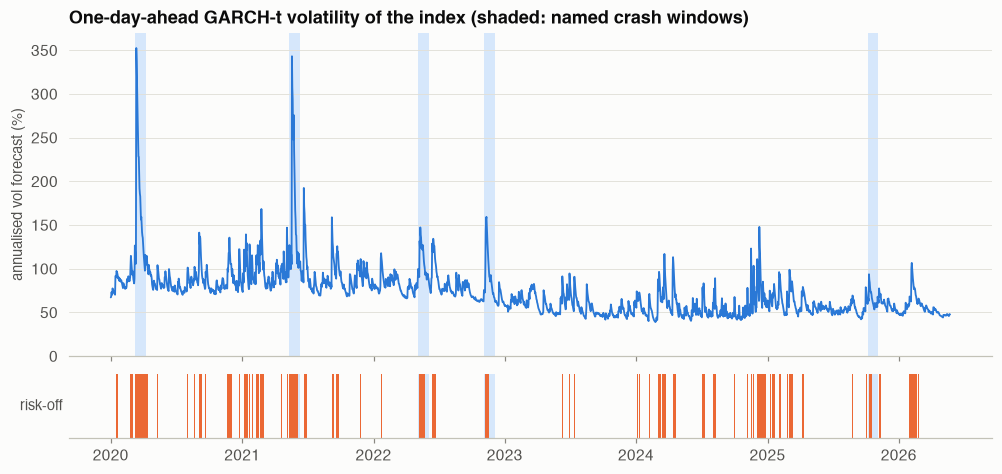

In [7]:
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(9, 4.2), sharex=True, height_ratios=[5, 1])
s = sig.loc[START:] * np.sqrt(365) * 100
for name, (a, b) in EVENTS.items():
    for a_ in (ax, ax2):
        a_.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=P.SEQ[0], alpha=0.8, lw=0, zorder=0)
ax.plot(s.index, s, color=P.C[0], lw=1.2)
ax.set_ylim(0, s.max() * 1.05)
ax.set_ylabel("annualised vol forecast (%)")
ax.set_title("One-day-ahead GARCH-t volatility of the index (shaded: named crash windows)")
ro = risk_off.loc[START:]
ax2.bar(ro.index[ro.to_numpy()], 1, width=1.0, color=P.C[1], linewidth=0)
ax2.set_yticks([]); ax2.set_ylim(0, 1); ax2.grid(False)
ax2.set_ylabel("risk-off", rotation=0, ha="right", va="center")
P.save(fig, "01_garch_filter")
flag = pd.DataFrame({"share of days risk-off": {n: risk_off.loc[a:b].mean() for n, (a, b) in EVENTS.items()}})
flag["first risk-off day in window"] = pd.Series({n: (risk_off.loc[a:b].idxmax().date() if risk_off.loc[a:b].any() else None)
                                                 for n, (a, b) in EVENTS.items()})
print(f"Risk-off on {risk_off.loc[START:].mean():.0%} of all days since 2020; "
      f"{risk_off.loc[START:][hv.loc[START:]].mean():.0%} of high-volatility-regime days")
flag

## Takeaways

* The five crashes cut the compounded mean log return by 16–58% within a month, and LINK was the hardest-hit coin in four of them.
* In the pooled crash windows the coins move together: average correlation is 0.84 against 0.54, and the volatility of the mean log return more than doubles. The unit-weight gap rises by about 7%. The fitted-hedge gap, using a ratio known only through the previous day, rises by about 32%. A unit gap is not the hedge that is traded. October 2025 is much less correlated than March 2020.
* Volatility is persistent (α + β between 0.97 and 1.00) and heavy-tailed (ν about 3–5) for every coin. The walk-forward GARCH-t filter flags almost all of the COVID and May 2021 windows, but only about half of Terra/LUNA, a third of FTX and a quarter of October 2025, where the shocks were short and sharp. A volatility filter can react only after volatility starts to rise.

Notebook 2 checks which pairs are cointegrated and how stable that is.